In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")

# Generación aleatoria pero coherente con la realidad financiera colombiana
np.random.seed(42)
bancos = ['Bancolombia', 'Banco de Bogotá', 'Davivienda', 'BBVA Colombia', 'Banco de Occidente', 'Scotiabank Colpatria', 'Banco AV Villas']
regiones_sede = ['Antioquia', 'Bogotá', 'Bogotá', 'Bogotá', 'Valle', 'Bogotá', 'Bogotá']
tipos = ['Nacional', 'Nacional', 'Nacional', 'Extranjero', 'Nacional', 'Extranjero', 'Nacional']

list_data = []
# Generamos registros trimestrales desde 2018 a 2026 (34 trimestres)
for i, banco in enumerate(bancos):
    activos_base = np.random.uniform(30000, 95000) if i < 3 else np.random.uniform(10000, 40000)
    for anio in range(2018, 2027):
        for trim in ['T1', 'T2', 'T3', 'T4']:
            if anio == 2026 and trim in ['T3', 'T4']: continue # Cortamos en 2026 T2
            
            # Crecimiento orgánico simulado con ruido de mercado
            factor_crecimiento = 1 + (0.02 * (anio - 2018)) + np.random.normal(0, 0.015)
            activos = activos_base * factor_crecimiento
            pasivos = activos * np.random.uniform(0.85, 0.89)
            patrimonio = activos - pasivos
            
            # Margen de intermediación y provisiones
            ingresos_intereses = activos * np.random.uniform(0.02, 0.035)
            gastos_intereses = pasivos * np.random.uniform(0.008, 0.015)
            utilidad_neta = (ingresos_intereses - gastos_intereses) * np.random.uniform(0.15, 0.3)
            
            # Carteras y riesgo
            cartera_total = activos * np.random.uniform(0.65, 0.75)
            cartera_vencida = cartera_total * np.random.uniform(0.03, 0.07) # Ruido de morosidad
            
            list_data.append({
                'Fecha_Corte': f"{anio}-{trim}",
                'Banco': banco.upper() if np.random.rand() > 0.2 else banco.lower(), # Texto sucio
                'Tipo_Capital': tipos[i],
                'Sede_Principal': regiones_sede[i],
                'Activos_MM': round(activos, 2),
                'Pasivos_MM': round(pasivos, 2),
                'Patrimonio_MM': round(patrimonio, 2),
                'Utilidad_Neta_Trimestre_MM': round(utilidad_neta, 2),
                'Cartera_Total_MM': round(cartera_total, 2),
                'Cartera_Vencida_MM': round(cartera_vencida, 2) if np.random.rand() > 0.05 else np.nan, # Nulos inducidos
                'Quejas_Recibidas': int(cartera_total * np.random.uniform(0.01, 0.02))
            })

df_sfc = pd.DataFrame(list_data)

# Inducir filas duplicadas exactas para la prueba de limpieza
df_sfc = pd.concat([df_sfc, df_sfc.sample(7)], ignore_index=True)

print(f"¡Dataset financiero cargado! Dimensiones: {df_sfc.shape[0]} filas y {df_sfc.shape[1]} columnas.")
print("Listo para iniciar la evaluación técnica guiada.")


¡Dataset financiero cargado! Dimensiones: 245 filas y 11 columnas.
Listo para iniciar la evaluación técnica guiada.


### 🧹 Ejercicio 1: Calidad de Datos y Estandarización (Nivel: Fácil - Filtro Inicial)

**Contexto:**
Los sistemas financieros reportan datos desde múltiples plataformas. Esto suele generar registros duplicados, inconsistencias en el uso de mayúsculas/minúsculas y valores faltantes (`NaN`) debido a desfases en los reportes de riesgo. Un analista junior debe garantizar que los datos estén impecables antes de calcular cualquier indicador financiero.

**Enunciado:**
Realiza las siguientes operaciones de limpieza sobre el DataFrame **`df_sfc`**:
1. **Eliminar Duplicados:** Detecta y remueve las filas duplicadas exactas que se encuentran en el dataset.
2. **Estandarizar Texto:** Transforma todos los nombres de la columna `Banco` a letras **mayúsculas** de manera uniforme.
3. **Tratamiento de Nulos:** La columna `Cartera_Vencida_MM` presenta valores nulos. Rellena esos campos vacíos utilizando la **mediana** de esa misma columna.

Al final, imprime el tamaño final del DataFrame con `.shape` y verifica que no queden nulos con `.isnull().sum()`.

**Pistas:**
<details>
<summary>💡 Ver pistas para el Ejercicio 1 (Limpieza)</summary>

1. **Remover duplicados:** Pandas cuenta con el método `df.drop_duplicates(inplace=True)`.
2. **Mayúsculas en Series:** Para modificar texto en una columna usas las funciones de string: `df['Columna'] = df['Columna'].str.upper()`.
3. **Imputación por mediana:** Puedes calcular la mediana con `df['Columna'].median()` y rellenar los nulos usando `df['Columna'].fillna(valor_mediana, inplace=True)`.
</details>


In [8]:
df_sfc.info()

<class 'pandas.DataFrame'>
RangeIndex: 245 entries, 0 to 244
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Fecha_Corte                 245 non-null    str    
 1   Banco                       245 non-null    str    
 2   Tipo_Capital                245 non-null    str    
 3   Sede_Principal              245 non-null    str    
 4   Activos_MM                  245 non-null    float64
 5   Pasivos_MM                  245 non-null    float64
 6   Patrimonio_MM               245 non-null    float64
 7   Utilidad_Neta_Trimestre_MM  245 non-null    float64
 8   Cartera_Total_MM            245 non-null    float64
 9   Cartera_Vencida_MM          230 non-null    float64
 10  Quejas_Recibidas            245 non-null    int64  
dtypes: float64(6), int64(1), str(4)
memory usage: 30.1 KB


In [ ]:
#Detectar duplicados y llevarlos a un dataframe de respaldo
df_duplicados = df_sfc[df_sfc.duplicated()].copy()
df_duplicados

,Fecha_Corte,Banco,Tipo_Capital,Sede_Principal,Activos_MM,Pasivos_MM,Patrimonio_MM,Utilidad_Neta_Trimestre_MM,Cartera_Total_MM,Cartera_Vencida_MM,Quejas_Recibidas
238,2021-T2,BANCO DE OCCIDENTE,Nacional,Valle,37654.90,33074.62,4580.27,78.70,28101.57,1386.58,293
239,2022-T3,DAVIVIENDA,Nacional,Bogotá,55756.72,47935.55,7821.17,287.87,38456.44,2181.38,729
240,2026-T1,SCOTIABANK COLPATRIA,Extranjero,Bogotá,20222.13,17624.56,2597.57,99.76,14806.85,669.52,178
241,2018-T1,BBVA COLOMBIA,Extranjero,Bogotá,25667.39,22309.97,3357.42,130.96,18655.76,871.42,231
242,2019-T3,bancolombia,Nacional,Antioquia,54334.23,47363.57,6970.66,89.72,40679.42,NaN,738
243,2020-T3,SCOTIABANK COLPATRIA,Extranjero,Bogotá,17861.19,15783.57,2077.61,84.55,11926.68,617.81,124
244,2020-T4,BANCO DE OCCIDENTE,Nacional,Valle,37043.05,31575.89,5467.16,153.61,25877.80,1042.13,466


In [10]:
#Eliminar duplicados
df_sfc = df_sfc.drop_duplicates()
df_sfc.info()

<class 'pandas.DataFrame'>
RangeIndex: 238 entries, 0 to 237
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Fecha_Corte                 238 non-null    str    
 1   Banco                       238 non-null    str    
 2   Tipo_Capital                238 non-null    str    
 3   Sede_Principal              238 non-null    str    
 4   Activos_MM                  238 non-null    float64
 5   Pasivos_MM                  238 non-null    float64
 6   Patrimonio_MM               238 non-null    float64
 7   Utilidad_Neta_Trimestre_MM  238 non-null    float64
 8   Cartera_Total_MM            238 non-null    float64
 9   Cartera_Vencida_MM          224 non-null    float64
 10  Quejas_Recibidas            238 non-null    int64  
dtypes: float64(6), int64(1), str(4)
memory usage: 29.4 KB


In [15]:
#Transformar a mayúsculas los registros de la columna banco
df_sfc['Banco'] = df_sfc['Banco'].str.upper()
df_sfc.head()

,Fecha_Corte,Banco,Tipo_Capital,Sede_Principal,Activos_MM,Pasivos_MM,Patrimonio_MM,Utilidad_Neta_Trimestre_MM,Cartera_Total_MM,Cartera_Vencida_MM,Quejas_Recibidas
0,2018-T1,BANCOLOMBIA,Nacional,Antioquia,53438.73,45756.37,7682.36,113.32,38519.02,1187.29,466
1,2018-T2,BANCOLOMBIA,Nacional,Antioquia,54605.07,46811.45,7793.62,175.68,37851.93,1576.50,489
2,2018-T3,BANCOLOMBIA,Nacional,Antioquia,53771.76,47394.81,6376.95,164.03,35201.41,1911.50,686
3,2018-T4,BANCOLOMBIA,Nacional,Antioquia,52600.94,46742.52,5858.41,200.26,37789.74,1799.02,390
4,2019-T1,BANCOLOMBIA,Nacional,Antioquia,55244.97,48422.26,6822.70,185.50,36930.46,2540.20,699


In [ ]:
#Para la columna Cartera_Vencida_MM imputar los vacíos con la mediana de esa columna

#Identificar los vacíos en la columna
df_sfc[df_sfc['Cartera_Vencida_MM'].isna()]

,Fecha_Corte,Banco,Tipo_Capital,Sede_Principal,Activos_MM,Pasivos_MM,Patrimonio_MM,Utilidad_Neta_Trimestre_MM,Cartera_Total_MM,Cartera_Vencida_MM,Quejas_Recibidas
6,2019-T3,BANCOLOMBIA,Nacional,Antioquia,54334.23,47363.57,6970.66,89.72,40679.42,NaN,738
32,2026-T1,BANCOLOMBIA,Nacional,Antioquia,63347.89,55395.75,7952.13,229.11,45976.92,NaN,478
45,2020-T4,BANCO DE BOGOTÁ,Nacional,Bogotá,72663.46,63459.52,9203.94,352.50,53542.79,NaN,1054
82,2021-T3,DAVIVIENDA,Nacional,Bogotá,54992.58,48053.36,6939.22,94.10,40683.81,NaN,598
89,2023-T2,DAVIVIENDA,Nacional,Bogotá,56431.97,49690.84,6741.12,122.18,41728.91,NaN,529
90,2023-T3,DAVIVIENDA,Nacional,Bogotá,58744.39,50538.71,8205.68,178.00,41271.99,NaN,790
91,2023-T4,DAVIVIENDA,Nacional,Bogotá,57590.35,49223.05,8367.30,270.80,41185.28,NaN,468
101,2026-T2,DAVIVIENDA,Nacional,Bogotá,60569.86,52256.65,8313.21,251.57,40781.44,NaN,764
118,2022-T1,BBVA COLOMBIA,Extranjero,Bogotá,28654.10,24811.69,3842.41,67.98,21187.12,NaN,349
136,2018-T1,BANCO DE OCCIDENTE,Nacional,Valle,35517.28,31423.23,4094.05,103.61,23288.99,NaN,261


In [19]:
#Calcular la mediana para la columna Cartera_Vencida_MM
mediana_cartera_vencida = df_sfc['Cartera_Vencida_MM'].median().round(2)
print(f'La mediana de la columna `Cartera_Vencida_MM` es: {mediana_cartera_vencida}')

La mediana de la columna `Cartera_Vencida_MM` es: 1263.32


In [22]:
#Imputar los vacíos de la columna Cartera_Vencida_MM con la mediana calculada
df_sfc['Cartera_Vencida_MM'] = df_sfc['Cartera_Vencida_MM'].fillna(mediana_cartera_vencida)

#Comprobar si quedan valores en blanco
print(df_sfc.isnull().sum())

Fecha_Corte                   0
Banco                         0
Tipo_Capital                  0
Sede_Principal                0
Activos_MM                    0
Pasivos_MM                    0
Patrimonio_MM                 0
Utilidad_Neta_Trimestre_MM    0
Cartera_Total_MM              0
Cartera_Vencida_MM            0
Quejas_Recibidas              0
dtype: int64


In [ ]:
#Hacer todo en una sola linea
df_sfc['Cartera_Vencida_MM'] = df_sfc['Cartera_Vencida_MM'].fillna(df_sfc['Cartera_Vencida_MM'].median().round(2))

### 📈 Ejercicio 2: Ingeniería de Métricas Financieras (Nivel: Intermedio)

**Contexto:**
En las pruebas de selección para entidades financieras (como Bancolombia o el Grupo Aval), un error común es evaluar a los bancos solo por el tamaño de sus activos o sus utilidades brutas. Los evaluadores buscan que conozcas e implementes dos indicadores fundamentales de eficiencia y riesgo regulados por la Superintendencia Financiera:
1. **ROA (Return on Assets / Rentabilidad sobre Activos):** Mide la eficiencia de la gerencia para generar utilidades con los activos que posee.
2. **ICV (Indicador de Calidad de Cartera Vencida):** Mide el porcentaje de la cartera de créditos que se encuentra en mora. Un ICV muy alto es señal de alerta por riesgo de impago.

**Enunciado:**
Crea dos nuevas columnas métricas en tu DataFrame **`df_sfc`**:
1. **`ROA`**: Que sea el resultado de dividir la utilidad neta (`Utilidad_Neta_Trimestre_MM`) entre los activos totales (`Activos_MM`), multiplicado por 100 para expresarlo en porcentaje.
2. **`ICV`**: Que sea el resultado de dividir la cartera en mora (`Cartera_Vencida_MM`) entre la cartera total (`Cartera_Total_MM`), multiplicado por 100 para expresarlo en porcentaje.

Al final, muestra en pantalla únicamente las columnas `Fecha_Corte`, `Banco`, `ROA` e `ICV` para las primeras 5 filas (`.head()`).

**Pistas:**
<details>
<summary>💡 Ver pistas para el Ejercicio 2 (Métricas)</summary>

1. **Creación y operaciones:** Recuerda la estructura para añadir columnas realizando operaciones matemáticas directas:  
   `df['Nueva_Columna'] = (df['ColumnaA'] / df['ColumnaB']) * 100`
2. **Selección de columnas:** Para mostrar solo un grupo específico de columnas al final, pasa una lista con sus nombres dentro de un doble juego de corchetes:  
   `df[['Columna1', 'Columna2', 'Columna3']].head()`
</details>


In [28]:
#Calcular columnas
df_sfc['ROA'] = (df_sfc['Utilidad_Neta_Trimestre_MM']/ df_sfc['Activos_MM'] * 100).round(2)
df_sfc['ICV'] = (df_sfc['Cartera_Vencida_MM']/ df_sfc['Cartera_Total_MM'] * 100).round(2)

df_sfc[['Fecha_Corte','Banco','ROA','ICV']].head(5)

,Fecha_Corte,Banco,ROA,ICV
0,2018-T1,BANCOLOMBIA,0.21,3.08
1,2018-T2,BANCOLOMBIA,0.32,4.16
2,2018-T3,BANCOLOMBIA,0.31,5.43
3,2018-T4,BANCOLOMBIA,0.38,4.76
4,2019-T1,BANCOLOMBIA,0.34,6.88


### 🔍 Ejercicio 3: Segmentación Estratégica y Detección de Alertas de Riesgo (Nivel: Avanzado)

**Contexto:**
La Superintendencia Financiera no solo vigila el comportamiento individual de cada entidad, sino que busca tendencias de riesgo de manera agregada según el origen del capital. En épocas de desaceleración económica, el capital extranjero y el nacional pueden comportarse de formas muy distintas frente a la morosidad de los clientes.

**Enunciado:**
Para este ejercicio debes realizar dos operaciones de agregación y análisis:
1. **Agrupación por Tipo de Capital:** Agrupa tu DataFrame utilizando la columna **`Tipo_Capital`** y calcula el **Promedio (Media)** de las variables **`ROA`** e **`ICV`**. Guarda este resumen en una variable llamada `rendimiento_por_capital`.
2. **Filtrado de Alertas Críticas:** Supongamos que el Banco de la República emite una alerta para vigilar a las entidades con problemas. Filtra el DataFrame original para encontrar únicamente los registros del año **2025 o 2026** donde el **`ICV`** haya sido **estrictamente mayor al 5.5%**. Muestra solo las columnas `Fecha_Corte`, `Banco` e `ICV` de estos casos críticos.

**Pistas:**
<details>
<summary>💡 Ver pistas para el Ejercicio 3</summary>

1. **Promedio en GroupBy:** Recuerda que puedes calcular promedios específicos usando una estructura como:  
   `df.groupby('Columna_Grupo')[['Columna1', 'Columna2']].mean()`
2. **Filtrado por texto de año:** Como la columna `Fecha_Corte` es de texto (ej. `'2025-T1'`), puedes comprobar si el registro pertenece a esos años usando el método de strings `.str.contains('2025|2026')` o usando comparaciones lógicas directas si aíslas el año.
3. **Condiciones simultáneas:** No olvides usar el operador `&` y envolver cada condición de tu filtro entre paréntesis: `df[(condicion_fecha) & (condicion_icv)]`.
</details>


In [ ]:
#Filtrar y agrupar en un nuevo dataframe con el promedio de las columnas indicadas
df_rendimiento_capital = df_sfc.groupby('Tipo_Capital')[['ROA', 'ICV']].agg('mean').round(2).reset_index()
df_rendimiento_capital

,Tipo_Capital,ROA,ICV
0,Extranjero,0.39,5.36
1,Nacional,0.36,5.01


In [41]:
#Filtrar en un nuevo dataframe de acuerdo a las condiciones dadas
#df_alertas_criticas = df_sfc[(df_sfc['ICV']> 5.5) & ((df_sfc['Fecha_Corte'].str.contains('2025') | (df_sfc['Fecha_Corte'].str.contains('2026'))) )].copy()

#Sirve igual pero con menos argumentos 
df_alertas_criticas = df_sfc[((df_sfc['ICV']> 5.5) & ((df_sfc['Fecha_Corte'].str.contains('2025|2026'))))].copy()


df_alertas_criticas[['Fecha_Corte','Banco', 'ICV']]

,Fecha_Corte,Banco,ICV
28,2025-T1,BANCOLOMBIA,6.29
31,2025-T4,BANCOLOMBIA,5.86
63,2025-T2,BANCO DE BOGOTÁ,5.58
65,2025-T4,BANCO DE BOGOTÁ,6.88
96,2025-T1,DAVIVIENDA,6.67
97,2025-T2,DAVIVIENDA,5.64
130,2025-T1,BBVA COLOMBIA,5.90
133,2025-T4,BBVA COLOMBIA,6.88
164,2025-T1,BANCO DE OCCIDENTE,6.86
165,2025-T2,BANCO DE OCCIDENTE,5.60


### 📊 Ejercicio 4: Gráfico de Tendencia Temporal de Riesgo (Nivel: Avanzado)

**Contexto:**
Detectar las alertas en una tabla es útil, pero los comités de riesgo necesitan ver la "película completa". Quieren entender si la morosidad de la banca ha venido subiendo de forma sistemática desde el 2018 o si los picos del 2025/2026 fueron anomalías temporales. Para esto, un analista de datos debe mapear las tendencias a lo largo del tiempo.

**Enunciado:**
Utilizando tu DataFrame original (**`df_sfc`**), crea un **Gráfico de Líneas Temporales** utilizando `seaborn` que muestre la evolución del **`ICV`** (Indicador de Cartera Vencida) a lo largo de los años. El gráfico debe cumplir con estos requerimientos corporativos:
1. El eje horizontal (X) debe representar el tiempo mediante la columna **`Fecha_Corte`**.
2. El eje vertical (Y) debe mostrar el promedio del **`ICV`**.
3. Grafica las tendencias segmentando por la columna **`Tipo_Capital`** (Nacional vs Extranjero) usando colores distintos.
4. Ajusta el tamaño del lienzo a `(12, 5)` y rota las etiquetas del eje X a **45 grados** para que los trimestres se puedan leer sin amontonarse.
5. Agrega un título descriptivo institucional y etiquetas limpias en los ejes.

**Pistas:**
<details>
<summary>💡 Ver pistas para el Ejercicio 4 (Gráfico de Líneas)</summary>

1. **Función de Líneas:** En Seaborn, los gráficos de tendencia se crean con la función `sns.lineplot(data=df_sfc, x='Columna_X', y='Columna_Y', hue='Columna_Segmento', marker='o')`. El parámetro `marker='o'` añade puntos en cada trimestre para que se vea más profesional.
2. **Rotar etiquetas en Matplotlib:** Las fechas de los trimestres se amontonan fácilmente. Puedes rotarlas usando la función:  
   `plt.xticks(rotation=45)` justo antes de tu `plt.show()`.
3. **Estilo limpio:** Recuerda definir el tamaño al principio con `plt.figure(figsize=(12, 5))`.
</details>


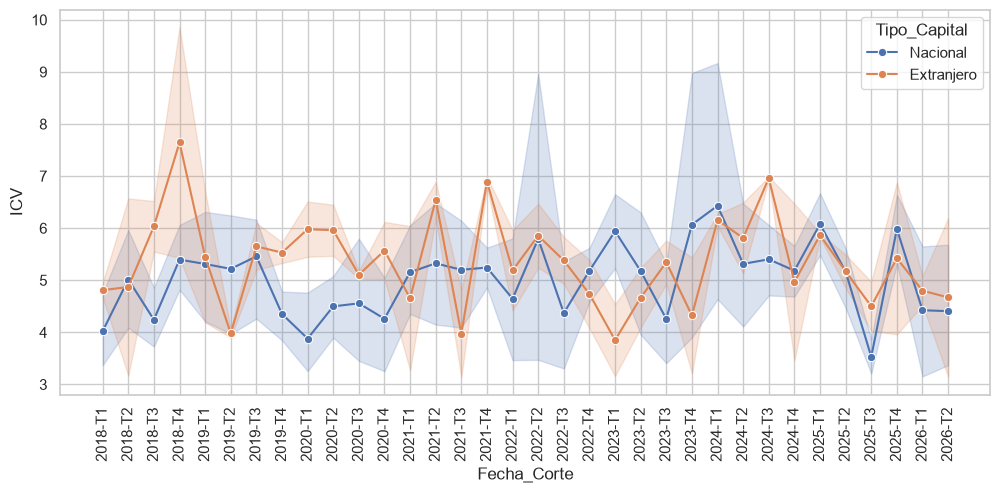

In [45]:
plt.figure(figsize=(12, 5))

sns.lineplot(data=df_sfc, x='Fecha_Corte', y='ICV', hue='Tipo_Capital', marker='o')

plt.xticks(rotation=90)

plt.show()

### 📊 Ejercicio 5: Distribución de Quejas y Detección de Outliers (Nivel: Avanzado)

**Contexto:**
La rentabilidad y el riesgo crediticio son solo dos patas de la mesa. La tercera es el riesgo reputacional. La Superintendencia Financiera sanciona fuertemente a las entidades que descuidan el servicio al cliente. Sin embargo, un volumen alto de quejas puede ser normal en un banco gigante (por simple escala) pero alarmante en un banco mediano. Los directores usan diagramas de caja para ver la dispersión e identificar qué entidades están teniendo picos anormales de reclamos.

**Enunciado:**
Utilizando tu DataFrame original (**`df_sfc`**), crea un **Gráfico de Cajas (Boxplot)** horizontal o vertical utilizando `seaborn` que compare la distribución de la columna **`Quejas_Recibidas`** para cada **`Banco`**. El gráfico debe cumplir con:
1. El eje correspondiente a las categorías debe mostrar los nombres de los **Bancos**.
2. El eje numérico debe medir las **Quejas_Recibidas**.
3. Ajusta el tamaño a `(12, 6)` para que el nombre de cada institución se lea perfectamente.
4. Pinta el gráfico usando una paleta corporativa clara (ej. `'Set2'` o `'pastel'`).

**Pistas:**
<details>
<summary>💡 Ver pistas para el Ejercicio 5 (Boxplot)</summary>

1. **Función Boxplot:** En Seaborn, se genera mediante `sns.boxplot(data=df_sfc, x='Columna_X', y='Columna_Y', palette='paleta')`.
2. **Orientación:** Si pones la variable categórica (`Banco`) en el eje `y` y la variable numérica (`Quejas_Recibidas`) en el eje `x`, el boxplot se dibujará de forma **horizontal**, lo cual es muy cómodo cuando los nombres de los bancos son largos.
3. **Identificación de Outliers:** Recuerda que en un Boxplot, los puntos sueltos que quedan por fuera de los "bigotes" (las líneas de los extremos) representan trimestres atípicos donde las quejas se dispararon sin control.
</details>


/var/folders/hd/rnl3k30523zbmtpjl_wmsp2m0000gn/T/ipykernel_16063/224391356.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sfc, x='Quejas_Recibidas', y='Banco', palette='muted')


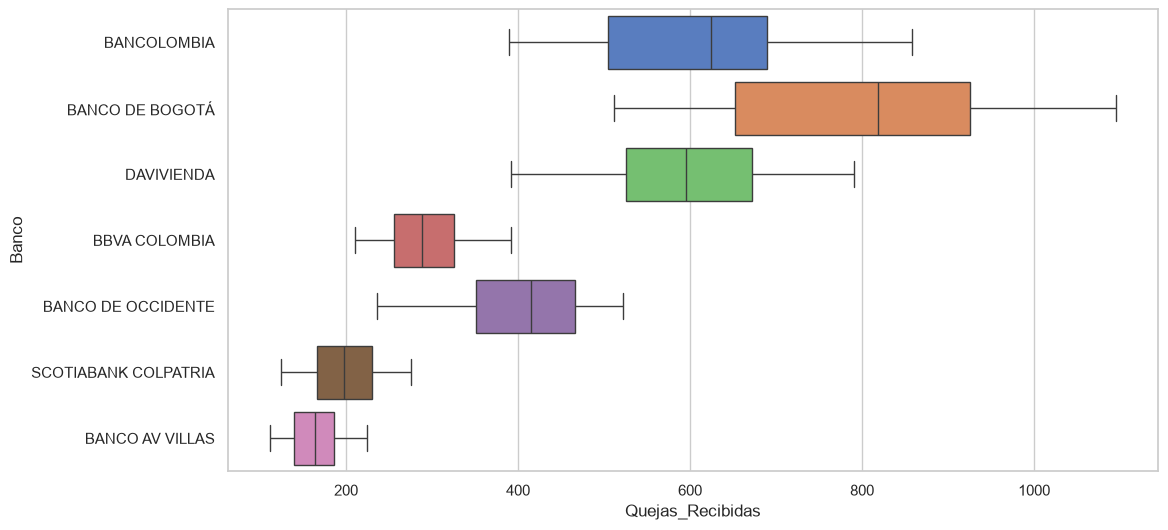

In [50]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_sfc, x='Quejas_Recibidas', y='Banco', palette='muted')

plt.show()
